# Nighttime Activity after the 2021 Henan Floods

How does a city return to its usual nighttime rhythm after a flood? I examine Zhengzhou, Kaifeng, and Xinxiang from June to September 2021, using light intensity as an activity signal. The analysis also compares simple methods for recognizing water in radar image patches.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    raise RuntimeError("Open this notebook from the repository root.")
sys.path.insert(0, str(ROOT))
from src.download import download_ntl, download_context
from src.lights import load_inputs, analyze, county_analysis, PERIODS
from src.radar import prepare_radar, run_benchmark
from src.plots import (plot_context, plot_coverage, plot_trajectories, plot_counties,
                       plot_diagnostics, plot_radar_gallery, plot_radar_scores)
pd.options.display.float_format = "{:.3f}".format

The following cell checks the local inputs and downloads missing files from their public sources. The nighttime-light downloader reads selected members of remote ZIP archives. It checks HTTP byte ranges and ZIP checksums. The radar archive has a published MD5 checksum. The supplied files let the remaining analysis run without new downloads.

In [2]:
light_downloads = download_ntl()
download_context()
radar_manifest = prepare_radar()
print("Public data inputs are available.")
print("Radar patch counts:", radar_manifest["subset_sizes"])

Public data inputs are available.
Radar patch counts: {'train': 96, 'val': 32, 'test': 64}


The following cell validates dates, raster coordinates, radiance values, and quality flags. The flag rasters are smaller than the light rasters, so nearest-neighbour reprojection aligns their categorical values. A pixel enters the fixed bright mask when its pre-event median is at least 5 nW cm-2 sr-1 and it has at least five noninterpolated baseline observations. The population layer provides relative spatial weights.

,city,study_bands,bright_pixels,flags_reprojected
1,Zhengzhou,45,10902.000,True
3,Kaifeng,44,1370.000,True
5,Xinxiang,44,2242.000,True


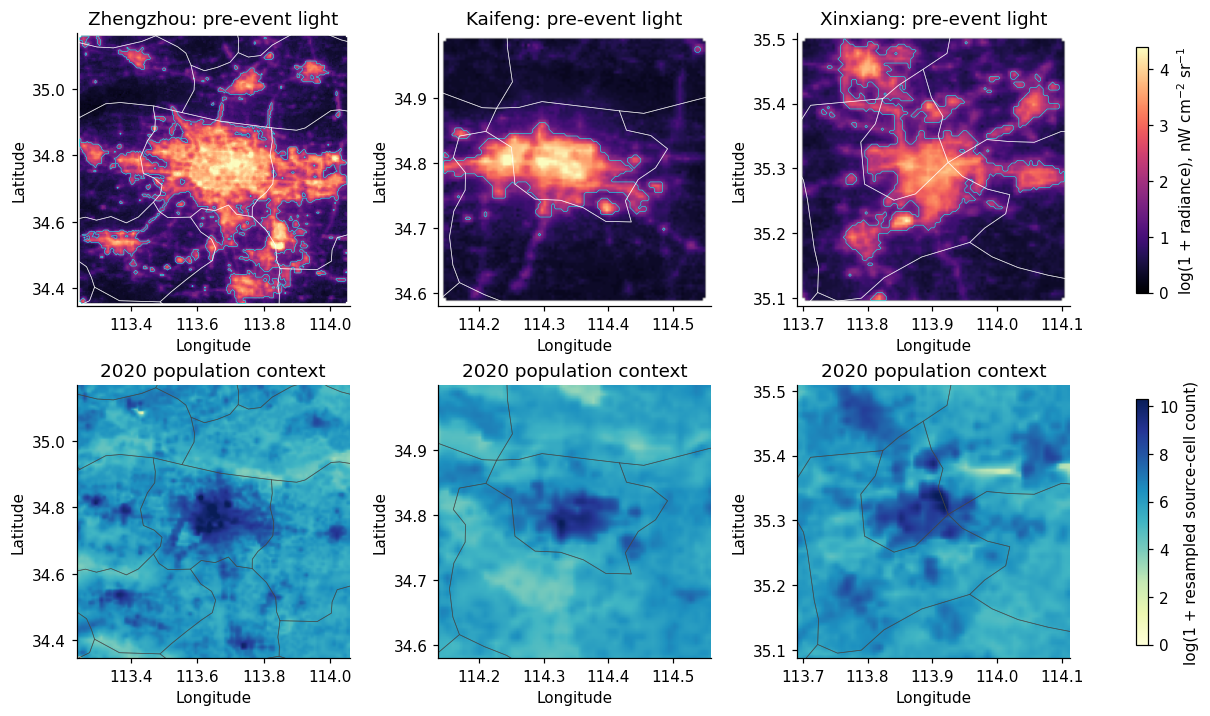

In [3]:
pairs, audit = load_inputs()
display(audit[audit.year == 2021][["city", "study_bands", "bright_pixels", "flags_reprojected"]])
fig = plot_context(pairs)
plt.show()
plt.close(fig)

The following cell averages light over the fixed mask. A date needs at least 70% noninterpolated bright-pixel coverage. Each city's median over June 1 to July 16 sets its baseline to one. Population-weighted averages emphasize pixels near larger estimated populations.

period,Pre-event,July 17-31,August 1-15,August 16-31,September
city,,,,,
Kaifeng,1.000,0.835,0.840,0.782,0.845
Xinxiang,1.000,0.847,0.910,0.979,0.939
Zhengzhou,1.000,0.779,0.790,0.888,0.860


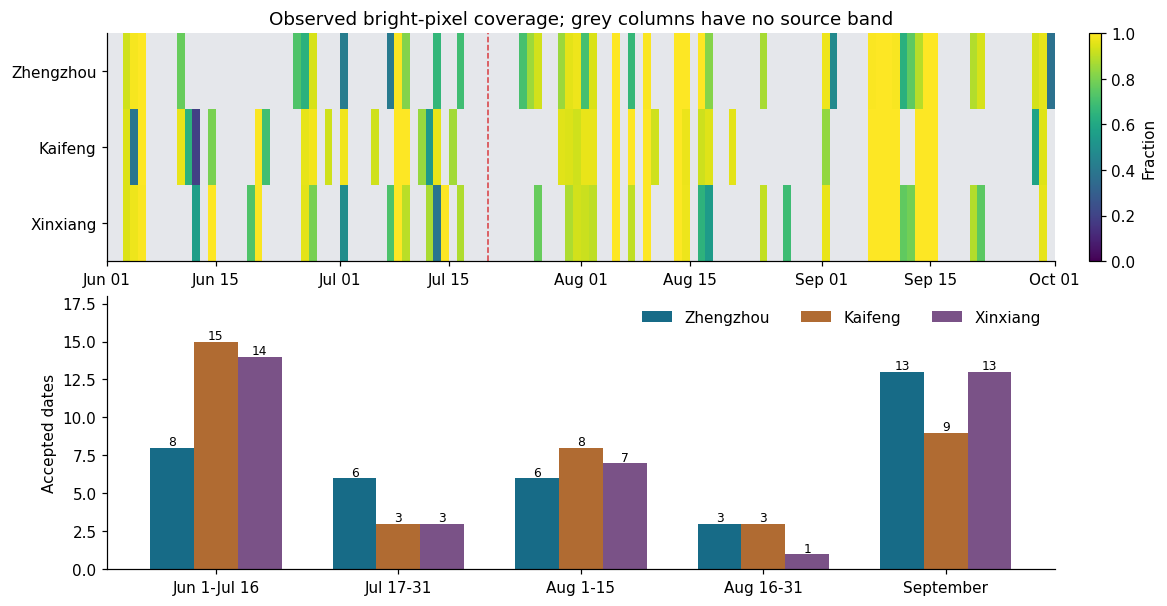

In [4]:
series, period_summary, returns, coverage_sensitivity = analyze(pairs)
display(period_summary.pivot(index="city", columns="period", values="median_index")
        .reindex(columns=list(PERIODS)))
fig = plot_coverage(series, period_summary)
plt.show()
plt.close(fig)

The next plot follows the light index through September. The trailing median needs three accepted observations within seven calendar days. The line has gaps where this support is absent. The July 17-31 interval provides an aftermath window; the source has no images for July 17-23 in these three city windows.

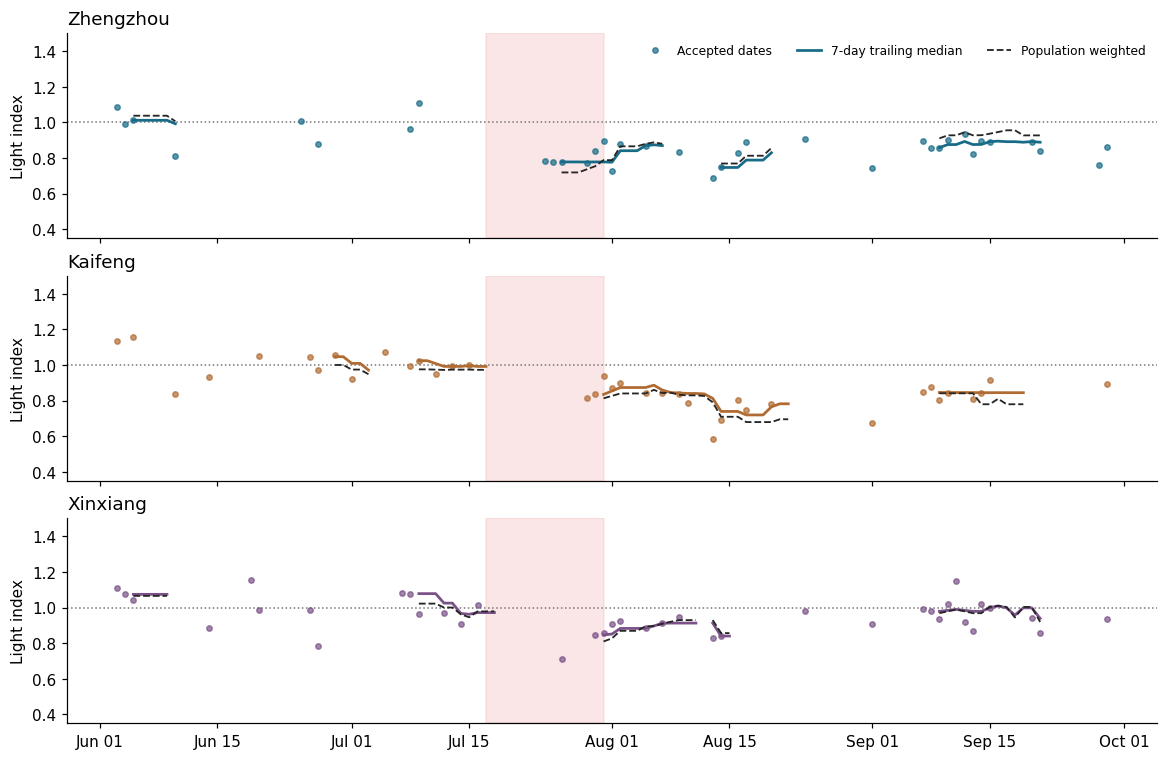

In [5]:
fig = plot_trajectories(series)
plt.show()
plt.close(fig)

The following cell intersects the city windows with historical county geometries. Each displayed value describes the bright part of a county inside the window. The table summarizes September variation among these spatial units.

,units,minimum,maximum
city,,,
Kaifeng,3,0.675,0.852
Xinxiang,5,0.852,1.058
Zhengzhou,9,0.623,0.961


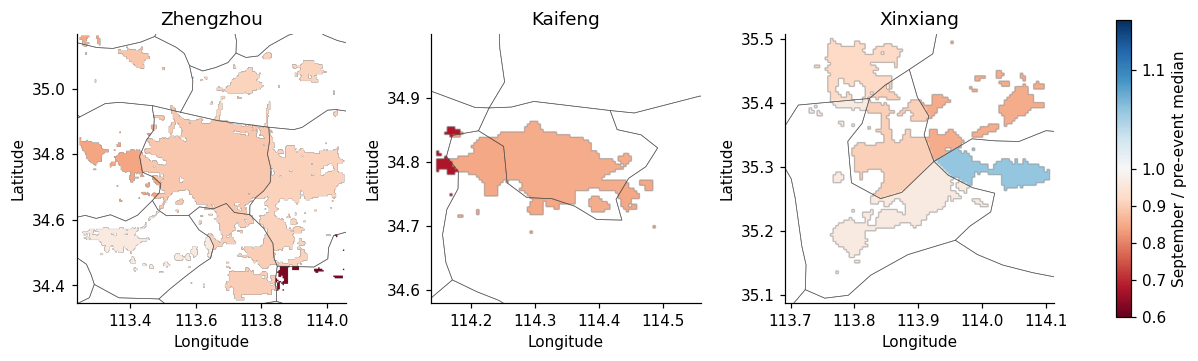

In [6]:
county_table, county_maps = county_analysis(pairs)
spatial_summary = county_table.groupby("city")["September"].agg(units="count", minimum="min", maximum="max")
spatial_summary.to_csv(ROOT / "outputs/tables/spatial_summary.csv")
display(spatial_summary)
fig = plot_counties(pairs, county_table, county_maps)
plt.show()
plt.close(fig)

The following cell changes the coverage threshold and compares the same calendar interval in 2020. These checks show how the choice of observations affects the index. A supported return requires an observed decline followed by three supported smoothed observations above the return threshold, with gaps of at most three days. The date describes a light-index threshold crossing.

,city,return_date,status
0,Zhengzhou,,Return not established by September 30
1,Kaifeng,,Return not established by September 30
2,Xinxiang,2021-09-09,Supported return


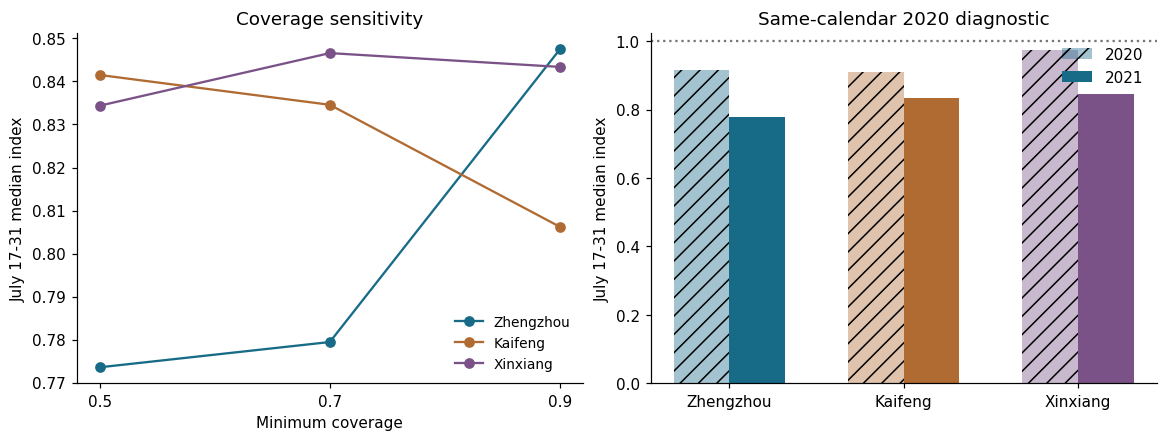

In [7]:
display(returns[(returns.coverage_threshold == 0.7) & (returns.return_threshold == 0.95)]
        [["city", "return_date", "status"]].reset_index(drop=True))
fig = plot_diagnostics(series, coverage_sensitivity)
plt.show()
plt.close(fig)

The following cell evaluates radar water recognition on a small subset of the published training, validation, and test splits. A baseline marks dark pixels as water. Validation data select its intensity threshold. A logistic model uses intensity, local mean, and local variability. The model learns from training pixels and selects its probability threshold using validation patches. Test labels only enter the final evaluation. The patch files contain no geographic coordinates, so their predictions cannot be overlaid on the city windows.

Training pixels: 196608
Validation-selected thresholds: 0.12000000000000001 0.7000000000000001


,model,precision,recall,f1,iou,iou_ci_low,iou_ci_high
0,Intensity 0.50,0.235,0.996,0.380,0.234,0.174,0.298
1,Tuned intensity,0.568,0.765,0.652,0.483,0.397,0.561
2,Local logistic,0.754,0.780,0.767,0.622,0.528,0.708


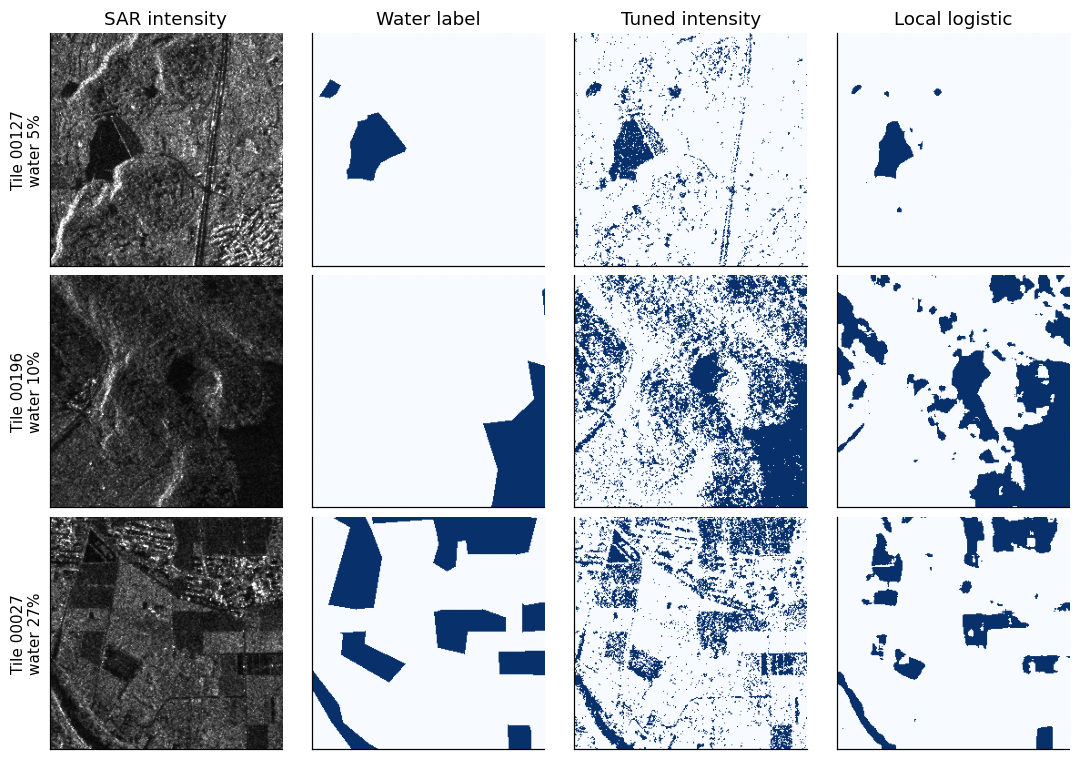

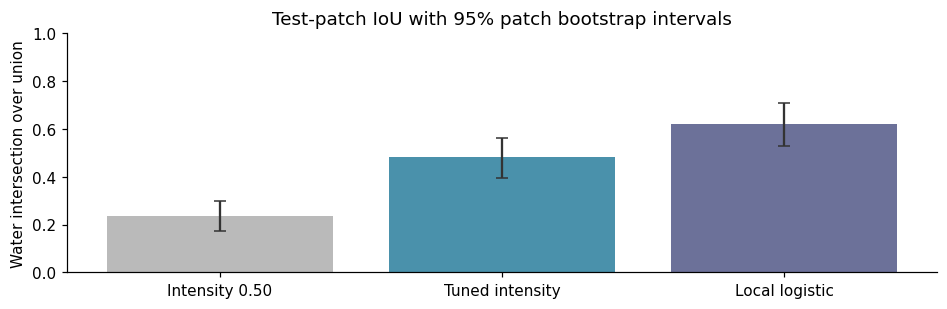

In [8]:
radar_metrics, radar_config, radar_splits, radar_predictors = run_benchmark()
display(radar_metrics[["model", "precision", "recall", "f1", "iou", "iou_ci_low", "iou_ci_high"]])
print("Training pixels:", radar_config["training_pixels"])
print("Validation-selected thresholds:", radar_config["intensity_threshold"], radar_config["probability_threshold"])
fig = plot_radar_gallery(radar_splits, radar_predictors)
plt.show()
plt.close(fig)
fig = plot_radar_scores(radar_metrics)
plt.show()
plt.close(fig)

The city observations show lower late-July light indices than the pre-event baseline, with different subsequent paths. Observation gaps restrict the timing of any recovery claim. The radar experiment tests water recognition on labeled patches; the city analysis tracks light variation over urban windows. Neither result measures economic losses or establishes a causal effect of the flood.